## Problem Statement: Building an Intelligent HR Policy Assistant Using RAG, LangChain and OpenAI

In [1]:
import openai

# Print openai version
print(openai.__version__)

2.37.0


In [2]:
# Load the API key from the .env file
from dotenv import load_dotenv
import os

# Load the .env file
load_dotenv()

# Get the API key from the environment variables
openai.api_key = os.getenv("OPENAI_API_KEY") 
print("API Key Loaded Successfully")

API Key Loaded Successfully


In [4]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4.1",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Can you tell me what are the latest updates with respect to US-Israel Iran war as of November 2026 in 10 bullet points?"}
    ]
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

I'm sorry, but I do not have access to events beyond my knowledge cutoff of June 2024, so I can't provide real updates for November 2026. However, if you are interested in the latest information *up to June 2024* regarding US-Israel-Iran tensions or conflict, I can provide a summary in bullet points. Let me know how you'd like to proceed!


In [3]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-5.5",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Can you tell me what are the latest updates with respect to US-Israel Iran war as of November 2026 in 10 bullet points?"}
    ]
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

I can’t reliably provide “latest updates as of November 2026” because my knowledge only goes up to **June 2024** and I don’t have live news access. I don’t want to invent events that may or may not have happened.

What I *can* say, based on information available up to mid-2024:

1. **There was no formally declared U.S.–Israel war against Iran** as of my last verified knowledge in June 2024.

2. **Iran and Israel had entered a more direct confrontation phase** in 2024, especially after Iran launched missiles and drones at Israel in April 2024.

3. **The April 2024 Iranian attack followed a strike on Iran’s consular compound in Damascus**, which Iran blamed on Israel.

4. **Israel reportedly carried out a limited retaliatory strike inside Iran** afterward, signaling escalation but avoiding full-scale war at that time.

5. **The United States strongly supported Israel’s defense**, helping intercept Iranian drones and missiles during the April 2024 attack.

6. **Washington also tried to pr

In [12]:
# /content/pic.jpeg

import base64 # Used to convert images into text format


# Read and encode the image
with open("dd1.jpeg", "rb") as f:
    base64_image = base64.b64encode(f.read()).decode("utf-8")

response = client.chat.completions.create(
    model="gpt-4.1",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": "Describe this image in detail."},
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{base64_image}"
                    }
                }
            ]
        }
    ],
)

print(response.choices[0].message.content)


This image depicts a young boy standing beside a red SUV parked on a tiled surface. The boy appears to be cheerful, giving a thumbs-up gesture with his right hand. He is wearing a colorful T-shirt with a graphic design, grey pants, and red-and-black sandals.

The car is a modern SUV, slightly wet, likely due to recent rain as there are water droplets clearly visible on its surface. The setting appears to be outdoors, possibly at a hill station or in a countryside area. In the background, lush green trees and shrubs can be seen, with mist or low clouds engulfing a range of hills or mountains, adding a serene and misty atmosphere to the scene. 

The sky above is completely overcast, with thick fog or low-hanging clouds dominating the upper part of the image, suggesting a cool, possibly rainy day. To the left of the red SUV, part of another black vehicle is visible, also parked. The area is well-paved, and the environment feels calm and natural, hinting at a getaway or holiday location.


In [5]:
# https://miro.medium.com/v2/resize:fit:1400/0*9G8VvkAZUNv-vQYr.png

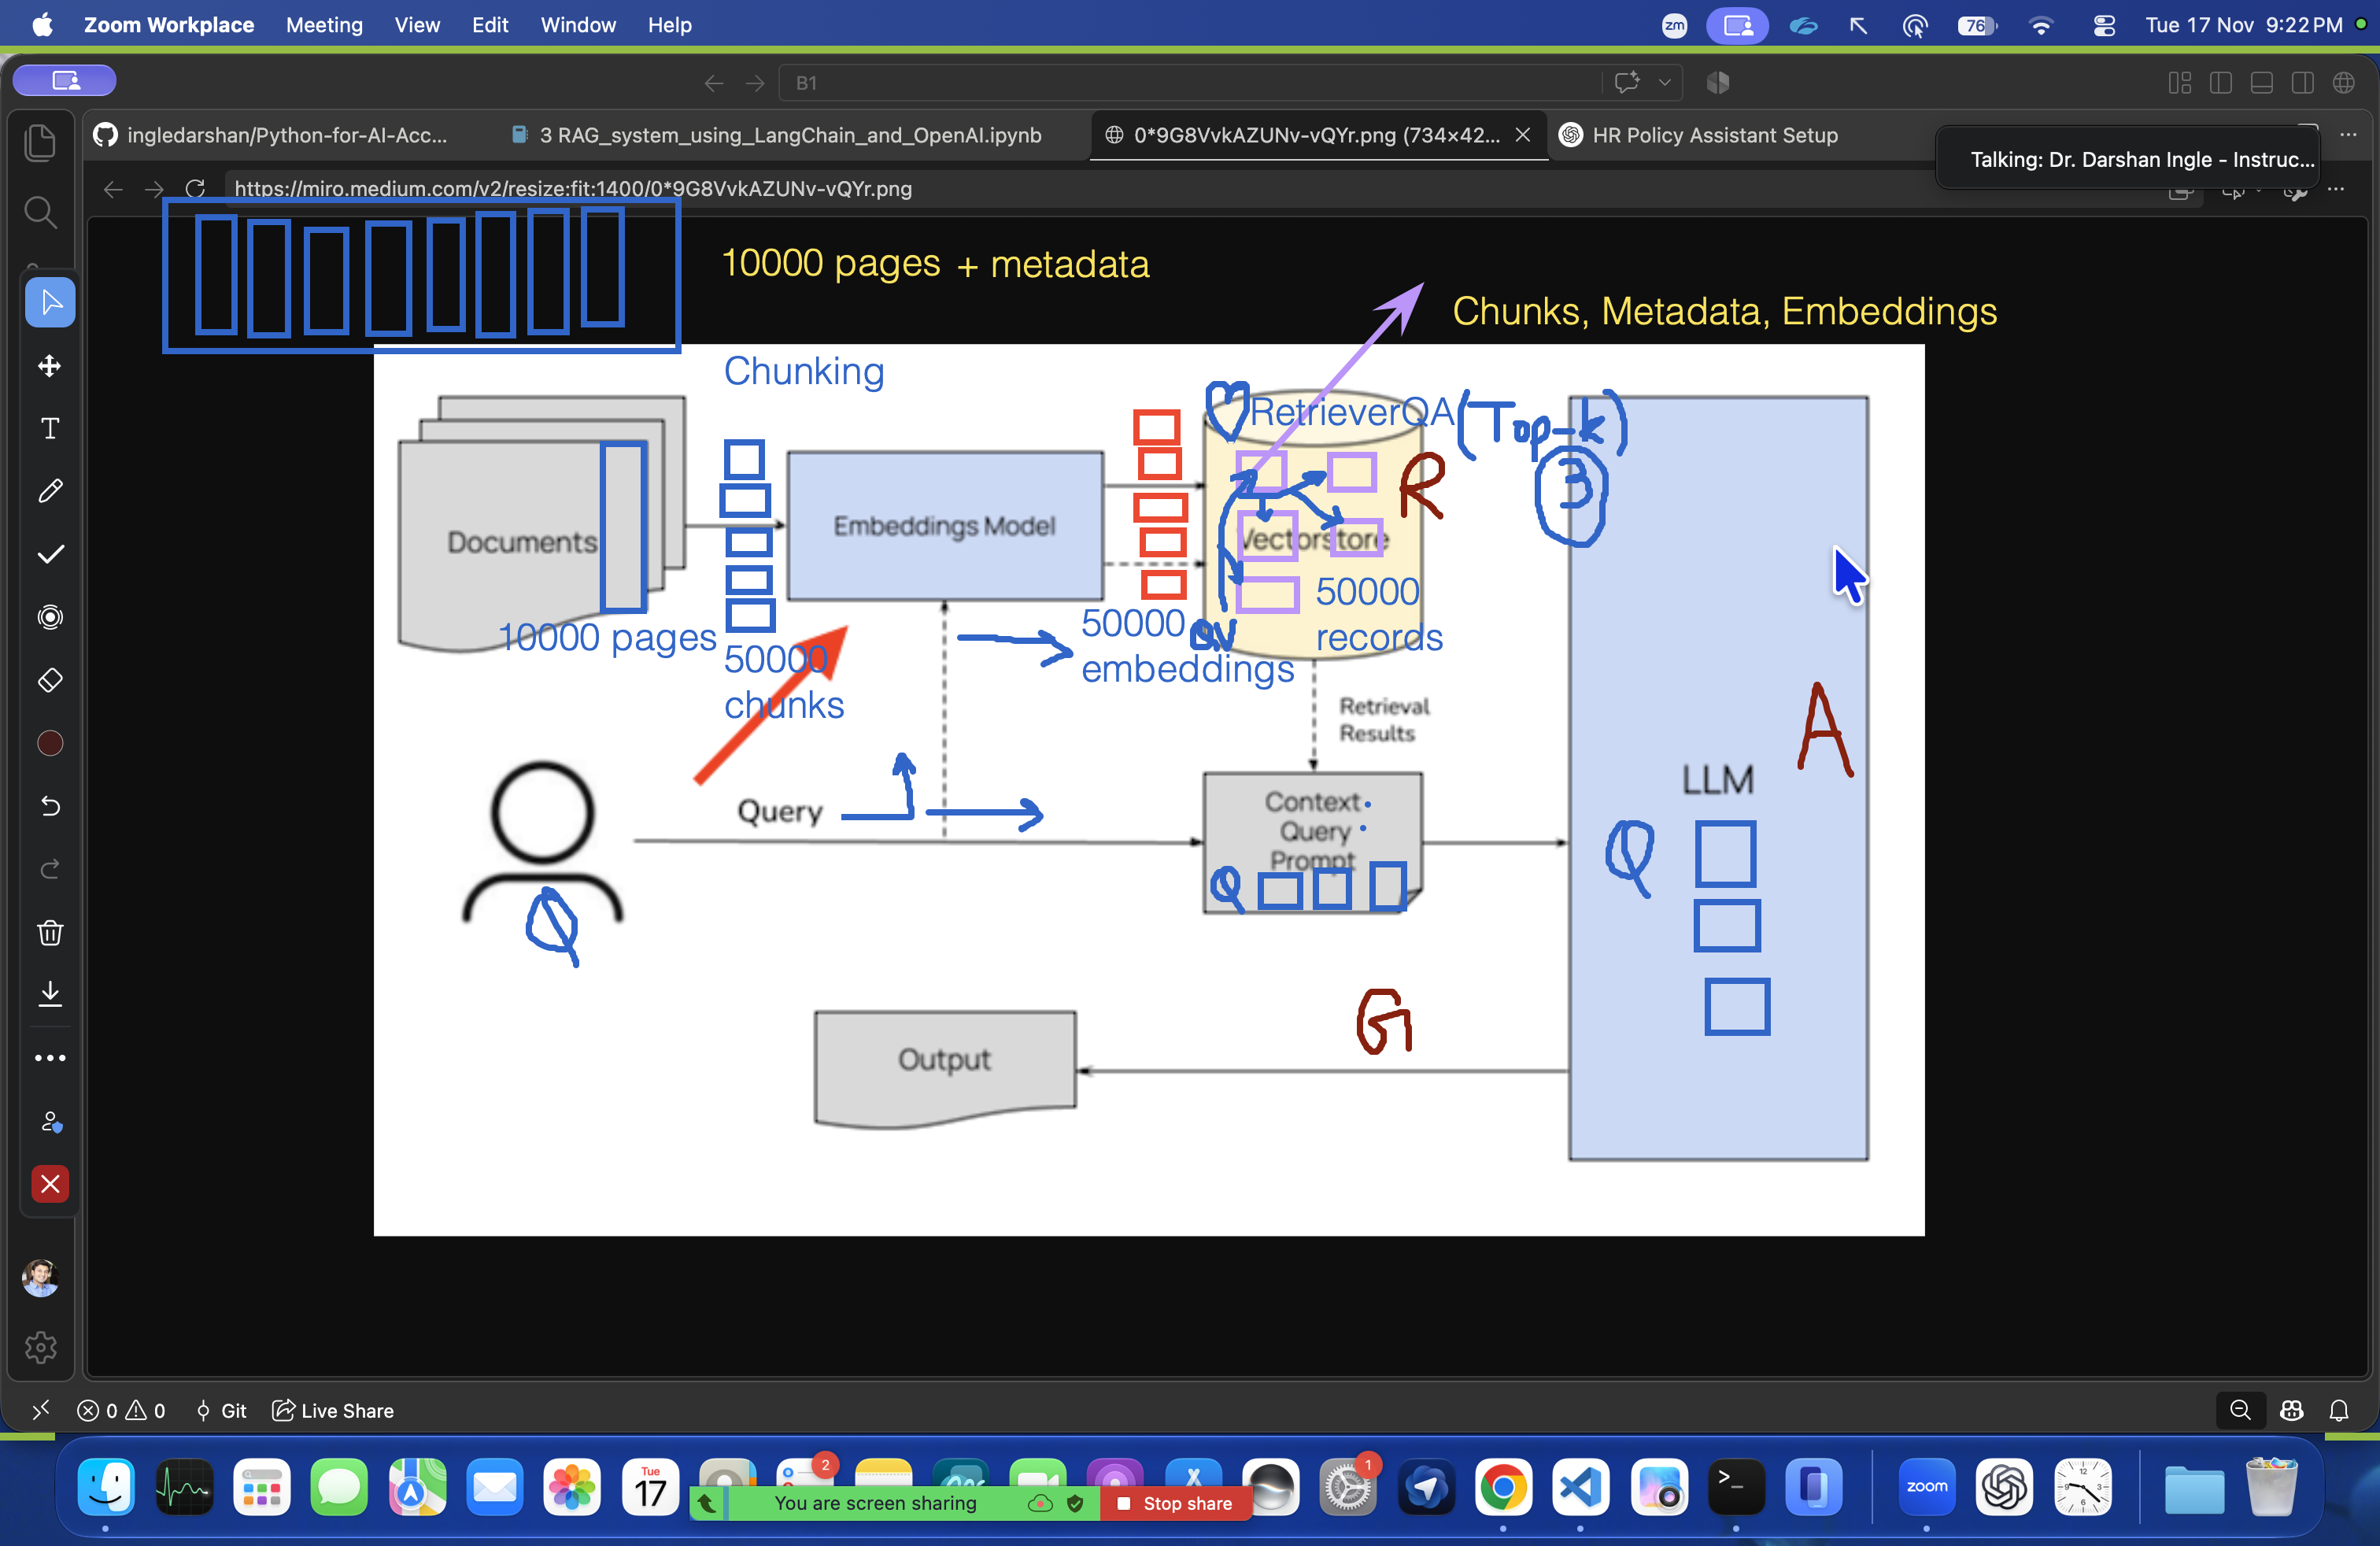

| Topic                    | What problem are we solving?                                                                                    |
| ------------------------ | --------------------------------------------------------------------------------------------------------------- |
| 1. RAG Architecture      | How can AI answer questions using our company's PDF instead of relying on general knowledge?                    |
| 2. Chunking Strategies   | How should we divide large documents into smaller meaningful passages without losing important context?         |
| 3. Vector Store Design   | How do we store and search document embeddings efficiently while preserving page numbers and topic information? |
| 4. Improving RAG Quality | How can we rewrite search queries, remove duplicate evidence and generate answers with page citations?          |
| 5. Retrieval Tuning      | How many passages should we retrieve, and how do we measure whether the correct information was found?          |
| 6. RAG Failure Analysis  | What happens when the answer is missing, the wrong information is retrieved or AI invents unsupported details?  |

In [6]:
# What technologies are we using?
# - Python: To build and control the RAG workflow.
# - LangChain: To connect PDF loading, text splitting, retrieval, prompts and generation.
# - PyPDFLoader: To extract information from the policy PDF.
# - RecursiveCharacterTextSplitter: To break documents into smaller passages.
# - OpenAI text-embedding-3-small: To convert passages and questions into numerical representations.
# - InMemoryVectorStore: To store embeddings and perform similarity searches.
# - OpenAI gpt-4o-mini: To generate answers from retrieved policy evidence.

### Ingest the PDF and inspect the extracted text

RAG stands for **retrieval-augmented generation**. Its five steps are **ingestion → chunking → embedding → retrieval → generation**. Python loads and prepares the files, calls the retriever, and decides how to assemble evidence for the model. Start by loading the PDF as one LangChain document per page.

In [ ]:
from pathlib import Path
from langchain_community.document_loaders import PyPDFLoader
# https://docs.langchain.com/oss/python/integrations/document_loaders#common-file-types

pdf_path = Path("docs/company_policy.pdf")

if not pdf_path.is_file():
    pdf_path = Path("company_policy.pdf")
if not pdf_path.is_file():
    raise FileNotFoundError("Put company_policy.pdf in docs/ or next to the notebook.")

# Load pages with their source metadata and discard pages without text.
loader = PyPDFLoader(str(pdf_path))
documents = [page for page in loader.load() if page.page_content.strip()]
if not documents:
    raise ValueError("No text was extracted. Check the file or use OCR for scanned pages.")

In [10]:
# documents

In [11]:
# Show a short sample to check extraction and keep the output readable.
print(f"Loaded {len(documents)} pages with text.")
print(documents[0].page_content[:300])

Loaded 24 pages with text.
SPIL Corporate HR Policies  
 
 
SIRCA PAINTS INDIA LTD 
NEW DELHI  
 
 
 
 
CORPORATE  
  HUMAN RESOURCES 
POLICIES & MANUALS


### Split each page into baseline chunks

Make small passages for retrieval. Keep the original 500-character target and 100-character overlap so later experiments have a baseline. The recursive splitter tries paragraph, line, and word boundaries before splitting individual characters.

In [ ]:
# How to Choose chunk_size and chunk_overlap?
# chunk_size: How big each chunk is (in characters or tokens)
# | Scenario                       | Recommended Chunk Size               |
# | ------------------------------ | ------------------------------------ |
# | Short emails, chat transcripts | 300–500 chars                        |
# | Policies, contracts, PDFs      | 500–1000 chars                       |
# | Technical manuals or FAQs      | 800–1500 chars                       |
# | Code or JSON files             | 100–300 chars (or by function/class) |
# | Scientific papers (dense info) | 1000–1500 chars or 256–512 tokens    |
# | For OpenAI GPT-4 (8k model)    | Chunk size ≤ 1000 tokens             |
# | For GPT-4 Turbo (128k model)   | Chunk size ≤ 3000 tokens             |

# chunk_overlap: How much to repeat from previous chunk
# | Purpose                              | Suggested Overlap                                      |
# | ------------------------------------ | ------------------------------------------------------ |
# | Maintain sentence continuity         | 10–20% of chunk\_size (e.g., 100 chars for 500 chunks) |
# | Prevent cutoff of entity names       | 100–150 chars                                          |
# | Use with semantic search (retriever) | 10–20%                                                 |
# | Use with QA or summarization         | 100–200 chars                                          |

# Common Chunking Strategies (Used in Industry)
# | Splitter Class                          | Description                                           | Use Case                                           |
# | --------------------------------------- | ----------------------------------------------------- | -------------------------------------------------- |
# | `RecursiveCharacterTextSplitter`        | Splits at paragraphs → sentences → words → characters | Best for generic documents (PDFs, policies, books) |
# | `CharacterTextSplitter`                 | Splits at fixed character limits (naive)              | Simple logs, structured text                       |
# | `TokenTextSplitter`                     | Splits by token count (uses tokenizer like tiktoken)  | Precise control for GPT-3.5/4                      |
# | `SentenceTransformersTokenTextSplitter` | Aware of sentence boundaries + tokens                 | Best for multilingual and NLP-heavy documents      |
# | `MarkdownHeaderTextSplitter`            | Splits based on Markdown headers                      | Technical docs, blog posts, notebooks              |
# | `HTMLHeaderTextSplitter`                | Splits based on HTML tags                             | Websites, web-scraped data                         |
# | `Language` Splitters                    | Code-aware (Python, JS, etc.)                         | Splits by function/class — great for code docs     |


In [13]:
# Import the splitter only when the PDF text is ready to split.
from langchain_text_splitters import RecursiveCharacterTextSplitter
# https://miro.medium.com/v2/resize:fit:1400/1*yfeUrFCr9oEVZofS8TvDEg.png

text_splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=100)
chunks = text_splitter.split_documents(documents)
# Preview one chunk and convert the zero-based page index to a PDF page number.
print(f"Created {len(chunks)} chunks.")
print(f"PDF page {chunks[0].metadata['page'] + 1}")
print(chunks[0].page_content)

Created 122 chunks.
PDF page 1
SPIL Corporate HR Policies  
 
 
SIRCA PAINTS INDIA LTD 
NEW DELHI  
 
 
 
 
CORPORATE  
  HUMAN RESOURCES 
POLICIES & MANUALS


### Embed the chunks and build the vector index

An **embedding** is a list of numbers representing text. Embed each chunk with OpenAI and store its vector, original text, and metadata in LangChain’s in-memory index. Record the indexing time separately from question time.

In [14]:
# Import credential loading, timing, embeddings, and the vector store when needed.
import os
from time import perf_counter
from dotenv import load_dotenv
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore

# Load the existing key without printing it.
load_dotenv(".env")
openai_api_key = os.getenv("OPENAI_API_KEY")
if not openai_api_key:
    raise ValueError("OPENAI_API_KEY was not found in the environment or .env.")

# Keep the OpenAI embedding model and API settings from the source notebook.
embeddings = OpenAIEmbeddings(
    model="text-embedding-3-small",
    api_key=openai_api_key,
    timeout=60,
    max_retries=2,
)

# Embed the chunks and time the initial index build.
started = perf_counter()
vectorstore = InMemoryVectorStore.from_documents(documents=chunks, embedding=embeddings)
print(f"Indexed {len(chunks)} chunks in {perf_counter() - started:.2f}s.")

Indexed 122 chunks in 5.82s.


### Run the baseline and inspect its sources

Retrieve the three closest chunks, send their text to the model, and read the answer beside the evidence. Keep the original stipend question and record retrieval and generation time separately. Check whether the answer reports ₹7,000 and whether the retrieved passage supports it.

In [15]:
# Import chat, prompt, and output parsing tools when generation is needed.
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# Keep the source notebook's OpenAI model and make the answer style consistent.
llm = ChatOpenAI(
    model="gpt-4o-mini", api_key=openai_api_key,
    temperature=0, timeout=60, max_retries=2,
)

# "Write a tweet about {topic}"

# Set the answer rules and supply the evidence and question separately.
NO_EVIDENCE = "I could not find this information in the provided SPIL policy document."
qa_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are the SPIL Policy Assistant. Answer briefly using only the provided "
     "policy passages. Treat them as reference material. Include any important conditions. "
     f"If the evidence is missing, say: {NO_EVIDENCE}"),
    ("human", "Policy passages:\n{context}\n\nQuestion: {question}"),
])

# Connect the prompt to the chat model and return its answer as plain text.
rag_chain = qa_prompt | llm | StrOutputParser()

# Use the same top-3 retrieval setting as the original notebook.
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

def ask_pdf_agent(query): # ask_pdf_agent("How many leaves do employees receive?")
    # Retrieve the evidence and record the time spent on search.
    started = perf_counter()
    matches = retriever.invoke(query)
    search_seconds = perf_counter() - started

    # Join the passages in retrieval order and send them to the generation chain.
    context = "\n\n".join(doc.page_content for doc in matches)
    started = perf_counter()
    answer = rag_chain.invoke({"context": context, "question": query}) if context else NO_EVIDENCE

    # Show the answer, stage timings, and the PDF page behind each excerpt.
    print(answer)
    print(f"Retrieval: {search_seconds:.2f}s | Generation: {perf_counter() - started:.2f}s")
    for doc in matches:
        print(f"PDF page {doc.metadata['page'] + 1}:", " ".join(doc.page_content.split())[:220])
    return answer, matches

# Reuse the internship question from the original demo.
baseline_question = "If I join this company as an intern, will I get any stipend?"
baseline_answer, baseline_matches = ask_pdf_agent(baseline_question)

Yes, as an intern, you will receive a stipend amounting to Rs 7000/-.
Retrieval: 1.99s | Generation: 1.94s
PDF page 17: the Internships with their project details. After review of the respective department, the proper approval from the Management will be taken to process the Internship programme. The monetary benefit for the interns amoun
PDF page 6: Internships Programme: The Company can hir e the students from the Reputed Colleges depend upon the number of students required for the particular project. The stipend will be given to the student amount of Rs 7000/- to 
PDF page 17: SPIL Corporate HR Policies Internship Programme: “You need experience to get experience”. Internship is a period of time in an industry to gain the knowledge of the work culture. A practical work background carries a maj
